# Class 200 — ทดลองทุกวิธี denoise (NIH, protocol แบบ Seminae)

**แยกจาก Notebook_3 release / run_all** ไม่อ่านหรือเขียน `runs/release_v4*` ใช้ข้อมูลและโฟลเดอร์ผลของตัวเอง

| ชุด | No Finding | Infiltration-only |
|---|---:|---:|
| Train | 200 | 200 |
| Validation | 40 | 40 |
| Test | 50 | 50 |

ภาพจาก NIH แยกคนไข้ตาม official split (train/val จาก `train_val_list.txt`, test จาก `test_list.txt`) seed 42 ทุกวิธีใช้ภาพชุดเดียวกัน
ResNet50 ImageNet ฝึกทุกชั้น, CE 2 class, Adam 1e-4, batch 32, 7 epochs, flip, ใช้ model epoch สุดท้าย, threshold = argmax, seed 42

21 วิธี: Baseline, Median L1–L4 (3/5/7/9), CLAHE+DWT L1–L4 (clip 1–4, ratio .05/.10/.20/.30),
DAE+CLAHE L1–L4 (clip 2/4/8/10), Pure DWT L1–L4 (ratio .05/.10/.20/.35) ตาม Seminae
DWT Low/Mid/High Only = db1 3 ระดับ เก็บ A3 / D3+D2 / D1 (mid/high เลื่อนเป็นเทา 128), Selective DWT = soft threshold เฉพาะ D1 ด้วย σ√(2lnN)

**วิธีใช้:** อัปโหลด `class200_methods_data.zip` ไป `MyDrive/nih -xray/class200_methods/` เลือก GPU แล้ว Run all
ผลแต่ละวิธีบันทึกทันทีใน `MyDrive/nih -xray/class200_methods/results_seed42/` ถ้า runtime หลุดให้ Run all ใหม่ จะข้ามวิธีที่เสร็จแล้ว


In [ ]:
from pathlib import Path
import shutil, subprocess, sys, zipfile
import torch

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "PyWavelets"])
try:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = Path("/content/drive/MyDrive/nih -xray/class200_methods")
    LOCAL = Path("/content")
except ImportError:
    WORK = Path.cwd()
    LOCAL = Path.cwd() / ".local"
DATA_ZIP = WORK / "class200_methods_data.zip"
DATA_DIR = LOCAL / "class200_data"
OUT_DIR = WORK / "results_seed42"   # separate from Notebook_3_release/runs
if not (DATA_DIR / "manifest.csv").is_file():
    if not DATA_ZIP.is_file():
        raise FileNotFoundError(f"Upload class200_methods_data.zip to {WORK}")
    with zipfile.ZipFile(DATA_ZIP) as archive:
        archive.extractall(LOCAL)
OUT_DIR.mkdir(parents=True, exist_ok=True)
if not torch.cuda.is_available():
    print("WARNING: no GPU; Runtime > Change runtime type > GPU")
print("Data:", DATA_DIR, "| Results:", OUT_DIR, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else None)


Mounted at /content/drive
Data: /content/class200_data | Results: /content/drive/MyDrive/nih -xray/class200_methods/results_seed42 | GPU: NVIDIA L4


## โค้ดการทดลอง (เหมือน `class200_methods.py`)

In [ ]:
"""Class-200 denoising method sweep on NIH, Seminae protocol. Separate from Notebook_3 release.

21 conditions (Baseline, Median/CLAHE+DWT/DAE+CLAHE/Pure DWT L1-L4, DWT low/mid/high
only, Selective DWT) are trained on the same 200+200 NIH images and tested on the same
50+50 test images. Training follows Seminae_source_code (1).ipynb: ResNet50 ImageNet,
every layer trainable, 2-class cross-entropy, Adam lr 1e-4, batch 32, 7 epochs,
random horizontal flip, last-epoch model, argmax threshold.

Images in the data ZIP are NIH originals converted to grayscale 512x512 (Seminae used
VinBigData 512px). Median and CLAHE+DWT run at 512 like Seminae; DAE, Pure DWT and
the band conditions run at 224 like Seminae. Every result is saved per condition so
a disconnected Colab session resumes at the next unfinished condition.
"""
from hashlib import sha256
from pathlib import Path
import json
import time

import cv2
import numpy as np
import pandas as pd
import pywt
import torch
from PIL import Image
from torch import nn

CNN_SIZE = 224
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)
TRAINING = {"epochs": 7, "batch_size": 32, "learning_rate": 1e-4, "seed": 42,
            "weights": "IMAGENET1K_V2", "trainable": "all", "loss": "cross_entropy_2class",
            "augmentation": "random_horizontal_flip", "checkpoint": "last_epoch", "threshold": "argmax"}
DAE_TRAINING = {"epochs": 5, "batch_size": 16, "learning_rate": 1e-3, "noise_std": 0.08, "seed": 42}
BAND_LEVEL = 3

# (id, display name, group, parameters); display names follow the requested result table.
CONDITIONS = [
    ("baseline", "Baseline (Raw CXR)", "baseline", {}),
    *[(f"median_L{i}", f"Median Filter L{i}", "median", {"kernel": k})
      for i, k in enumerate((3, 5, 7, 9), 1)],
    *[(f"clahe_dwt_L{i}", f"CLAHE + DWT L{i}", "clahe_dwt", {"clip_limit": c, "thresh_ratio": r})
      for i, (c, r) in enumerate(((1.0, .05), (2.0, .10), (3.0, .20), (4.0, .30)), 1)],
    *[(f"dae_clahe_L{i}", f"DAE + CLAHE L{i}", "dae_clahe", {"clip_limit": c})
      for i, c in enumerate((2.0, 4.0, 8.0, 10.0), 1)],
    *[(f"pure_dwt_L{i}", f"Pure DWT L{i}", "pure_dwt", {"thresh_ratio": r})
      for i, r in enumerate((.05, .10, .20, .35), 1)],
    ("dwt_low", "DWT Low Frequency Only", "dwt_band", {"band": "low", "level": BAND_LEVEL}),
    ("dwt_mid", "DWT Mid Frequency Only", "dwt_band", {"band": "mid", "level": BAND_LEVEL}),
    ("dwt_high", "DWT High Frequency Only", "dwt_band", {"band": "high", "level": BAND_LEVEL}),
    ("selective_dwt", "Selective DWT", "selective_dwt", {"level": BAND_LEVEL}),
]
CONDITION_IDS = [c[0] for c in CONDITIONS]
DISPLAY = {c[0]: c[1] for c in CONDITIONS}


def digest(value):
    return sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()


def file_hash(path):
    return sha256(Path(path).read_bytes()).hexdigest()


# ----------------------------------------------------------------- data

def load_data(data_dir):
    """Return manifest frame and grayscale 512 images keyed by image name."""
    data_dir = Path(data_dir)
    manifest = pd.read_csv(data_dir / "manifest.csv")
    images = {}
    for name in manifest["image"]:
        image = cv2.imread(str(data_dir / "images" / name), cv2.IMREAD_GRAYSCALE)
        if image is None:
            raise FileNotFoundError(f"Missing image {name}")
        images[name] = image
    return manifest, images


def resize_224(image):
    """Seminae resized with torchvision Resize on PIL images (bilinear)."""
    if image.shape == (CNN_SIZE, CNN_SIZE):
        return image
    return np.array(Image.fromarray(image).resize((CNN_SIZE, CNN_SIZE), Image.BILINEAR))


# ----------------------------------------------------------- denoising

def median_filter(image, kernel):
    return cv2.medianBlur(image, kernel)


def _soft(coefficient, threshold):
    # pywt returns NaN for zero coefficients when the threshold is 0 (flat band); keep them instead.
    return pywt.threshold(coefficient, threshold, mode="soft") if threshold > 0 else coefficient


def _soft_detail(LL, details, threshold, wavelet="db1"):
    bands = tuple(_soft(d, threshold) for d in details)
    return pywt.idwt2((LL, bands), wavelet)


def clahe_dwt(image, clip_limit, thresh_ratio):
    """Seminae apply_clahe_dwt: CLAHE, one-level db1, soft threshold ratio*max detail."""
    enhanced = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8)).apply(image)
    LL, details = pywt.dwt2(enhanced.astype(np.float32), "db1")
    threshold = thresh_ratio * np.max([np.abs(d) for d in details])
    return np.clip(_soft_detail(LL, details, threshold), 0, 255).astype(np.uint8)


def pure_dwt(image, thresh_ratio):
    """Seminae apply_pure_dwt on the 224 image."""
    LL, details = pywt.dwt2(image.astype(np.float32), "db1")
    threshold = thresh_ratio * np.max([np.abs(d) for d in details])
    return np.clip(_soft_detail(LL, details, threshold), 0, 255).astype(np.uint8)


def dwt_band(image, band, level=BAND_LEVEL):
    """Reconstruct one frequency band: low=A3, mid=D3+D2, high=D1 (db1, 3 levels).

    Mid/high have no DC component, so they are shifted to grey 128 before clipping.
    """
    coeffs = pywt.wavedec2(image.astype(np.float64), "db1", level=level)
    keep_details = {"low": set(), "mid": set(range(1, level)), "high": {level}}[band]
    kept = [coeffs[0] if band == "low" else np.zeros_like(coeffs[0])]
    for index, details in enumerate(coeffs[1:], 1):  # index 1 = coarsest, level = finest (D1)
        kept.append(details if index in keep_details else tuple(np.zeros_like(d) for d in details))
    result = pywt.waverec2(kept, "db1")[:image.shape[0], :image.shape[1]]
    if band != "low":
        result = result + 128
    return np.clip(np.round(result), 0, 255).astype(np.uint8)


def selective_dwt(image, level=BAND_LEVEL):
    """Soft-threshold only D1 with the universal threshold sigma*sqrt(2 ln N); keep A3, D3, D2."""
    coeffs = pywt.wavedec2(image.astype(np.float64), "db1", level=level)
    finest = coeffs[-1]
    sigma = np.median(np.abs(finest[2])) / 0.6745
    threshold = sigma * np.sqrt(2 * np.log(image.size))
    coeffs[-1] = tuple(_soft(d, threshold) for d in finest)
    result = pywt.waverec2(coeffs, "db1")[:image.shape[0], :image.shape[1]]
    return np.clip(np.round(result), 0, 255).astype(np.uint8)


class ConvDAE(nn.Module):
    """Seminae ConvDAE: two conv/pool encoders, two transposed-conv decoders, sigmoid output."""

    def __init__(self):
        super().__init__()
        self.enc1 = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2))
        self.enc2 = nn.Sequential(nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(inplace=True), nn.MaxPool2d(2, 2))
        self.dec1 = nn.Sequential(nn.ConvTranspose2d(64, 32, 2, stride=2), nn.BatchNorm2d(32), nn.ReLU(inplace=True))
        self.dec2 = nn.Sequential(nn.ConvTranspose2d(32, 1, 2, stride=2), nn.Sigmoid())

    def forward(self, x):
        return self.dec2(self.dec1(self.enc2(self.enc1(x))))


def train_dae(train_images, out_dir, device, settings=DAE_TRAINING, log=print):
    """Train once on the train split (unsupervised, Gaussian noise) and reuse dae.pt afterwards."""
    path = Path(out_dir) / "dae.pt"
    model = ConvDAE().to(device)
    record = {"settings": settings, "train_hash": digest(sorted(train_images))}
    if path.exists():
        saved = torch.load(path, map_location=device, weights_only=False)
        if saved["record"] == record:
            model.load_state_dict(saved["state"])
            log(f"DAE: reuse {path}")
            return model.eval()
        raise ValueError(f"{path} was trained on other data/settings; move it aside")
    torch.manual_seed(settings["seed"])
    generator = torch.Generator().manual_seed(settings["seed"])
    clean = torch.from_numpy(np.stack([resize_224(train_images[k]) for k in sorted(train_images)])).float().div(255)[:, None]
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
    criterion = nn.MSELoss()
    model.train()
    for epoch in range(1, settings["epochs"] + 1):
        order = torch.randperm(len(clean), generator=generator)
        total = 0.0
        for start in range(0, len(clean), settings["batch_size"]):
            batch = clean[order[start:start + settings["batch_size"]]].to(device)
            noisy = torch.clamp(batch + torch.randn_like(batch) * settings["noise_std"], 0, 1)
            optimizer.zero_grad()
            loss = criterion(model(noisy), batch)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch)
        log(f"DAE epoch {epoch}/{settings['epochs']} loss {total / len(clean):.5f}")
    torch.save({"state": model.state_dict(), "record": record}, path)
    return model.eval()


@torch.no_grad()
def dae_denoise(image_224, dae, device):
    tensor = torch.from_numpy(image_224).float().div(255)[None, None].to(device)
    return np.clip(dae(tensor)[0, 0].cpu().numpy() * 255, 0, 255).astype(np.uint8)


def process(image_512, condition_id, dae=None, device="cpu"):
    """One grayscale 512 image -> processed grayscale 224 image for this condition."""
    _, _, group, p = next(c for c in CONDITIONS if c[0] == condition_id)
    if group == "baseline":
        return resize_224(image_512)
    if group == "median":
        return resize_224(median_filter(image_512, p["kernel"]))
    if group == "clahe_dwt":
        return resize_224(clahe_dwt(image_512, p["clip_limit"], p["thresh_ratio"]))
    # Seminae resized to 224 with cv2 before DAE / pure DWT.
    small = cv2.resize(image_512, (CNN_SIZE, CNN_SIZE))
    if group == "dae_clahe":
        if dae is None:
            raise RuntimeError("DAE conditions need the trained DAE")
        denoised = dae_denoise(small, dae, device)
        return cv2.createCLAHE(clipLimit=p["clip_limit"], tileGridSize=(8, 8)).apply(denoised)
    if group == "pure_dwt":
        return pure_dwt(small, p["thresh_ratio"])
    if group == "dwt_band":
        return dwt_band(small, p["band"], p["level"])
    if group == "selective_dwt":
        return selective_dwt(small, p["level"])
    raise ValueError(f"Unknown group {group}")


# ------------------------------------------------------------ training

def to_tensor(images):
    x = torch.from_numpy(np.stack(images)).float().div(255)[:, None].expand(-1, 3, -1, -1)
    return (x - MEAN) / STD


def build_model():
    from torchvision.models import ResNet50_Weights, resnet50
    model = resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model


@torch.no_grad()
def predict(model, x, device, batch_size=64):
    model.eval()
    probs = []
    for start in range(0, len(x), batch_size):
        logits = model(x[start:start + batch_size].to(device))
        probs.append(torch.softmax(logits, 1).cpu())
    return torch.cat(probs).numpy()


def scores(targets, probs):
    from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                                 recall_score, roc_auc_score)
    predictions = probs.argmax(1)
    return {"accuracy": accuracy_score(targets, predictions),
            "precision": precision_score(targets, predictions, zero_division=0),
            "recall": recall_score(targets, predictions, zero_division=0),
            "f1": f1_score(targets, predictions, zero_division=0),
            "roc_auc": roc_auc_score(targets, probs[:, 1]),
            "confusion_matrix": confusion_matrix(targets, predictions, labels=[0, 1]).tolist()}


def train_condition(condition_id, manifest, processed, device, settings=TRAINING, log=print):
    """processed: image name -> uint8 224 image. Same seed, order and init for every condition."""
    split = {name: manifest[manifest["split"] == name].reset_index(drop=True) for name in ("train", "validation", "test")}
    x = {name: to_tensor([processed[i] for i in frame["image"]]) for name, frame in split.items()}
    y = {name: torch.tensor(frame["target"].to_numpy()) for name, frame in split.items()}
    torch.manual_seed(settings["seed"])
    np.random.seed(settings["seed"])
    model = build_model().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["learning_rate"])
    criterion = nn.CrossEntropyLoss()
    generator = torch.Generator().manual_seed(settings["seed"])
    history = []
    started = time.time()
    for epoch in range(1, settings["epochs"] + 1):
        model.train()
        order = torch.randperm(len(x["train"]), generator=generator)
        total, correct = 0.0, 0
        for start in range(0, len(order), settings["batch_size"]):
            index = order[start:start + settings["batch_size"]]
            images = x["train"][index]
            flip = torch.rand(len(index), generator=generator) < 0.5
            images[flip] = images[flip].flip(-1)
            images, labels = images.to(device), y["train"][index].to(device)
            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            total += loss.item() * len(index)
            correct += (logits.argmax(1) == labels).sum().item()
        val = predict(model, x["validation"], device)
        val_loss = nn.functional.nll_loss(torch.log(torch.from_numpy(val).clamp_min(1e-12)), y["validation"]).item()
        history.append({"epoch": epoch, "train_loss": total / len(order), "train_acc": correct / len(order),
                        "val_loss": val_loss, "val_acc": float((val.argmax(1) == y["validation"].numpy()).mean())})
        h = history[-1]
        log(f"  {condition_id} epoch {epoch}/{settings['epochs']} loss {h['train_loss']:.4f} "
            f"train_acc {h['train_acc']:.3f} val_loss {h['val_loss']:.4f} val_acc {h['val_acc']:.3f}")
    test = predict(model, x["test"], device)
    predictions = split["test"][["image", "patient_id", "target"]].assign(prob_infiltration=test[:, 1])
    return {"condition_id": condition_id, "display_name": DISPLAY[condition_id],
            "seconds": round(time.time() - started, 1), "history": history,
            **scores(y["test"].numpy(), test)}, predictions


# --------------------------------------------------------------- sweep

def run_all(data_dir, out_dir, condition_ids=None, device=None, settings=TRAINING, log=print):
    """Train every unfinished condition; finished ones are skipped only if protocol/data match."""
    device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
    out_dir = Path(out_dir)
    (out_dir / "conditions").mkdir(parents=True, exist_ok=True)
    manifest, images = load_data(data_dir)
    signature = {"training": settings, "dae": DAE_TRAINING, "conditions": CONDITIONS,
                 "manifest_sha256": file_hash(Path(data_dir) / "manifest.csv")}
    log(f"Device {device} | counts {manifest.groupby(['split', 'target']).size().to_dict()}")
    dae = None
    for condition_id in condition_ids or CONDITION_IDS:
        path = out_dir / "conditions" / f"{condition_id}.json"
        if path.exists():
            saved = json.loads(path.read_text(encoding="utf-8"))
            if saved.get("signature_sha256") == digest(signature):
                log(f"[skip] {DISPLAY[condition_id]} already done: AUC {saved['roc_auc']:.4f}")
                continue
            raise ValueError(f"{path} came from another protocol/data; use a new OUT_DIR")
        log(f"\n>>> {DISPLAY[condition_id]}")
        if condition_id.startswith("dae_clahe") and dae is None:
            train_names = manifest.loc[manifest["split"] == "train", "image"]
            dae = train_dae({k: images[k] for k in train_names}, out_dir, device, log=log)
        processed = {name: process(image, condition_id, dae, device) for name, image in images.items()}
        result, predictions = train_condition(condition_id, manifest, processed, device, settings, log)
        result["signature_sha256"] = digest(signature)
        predictions.to_csv(out_dir / "conditions" / f"{condition_id}_test_predictions.csv", index=False)
        temporary = path.with_suffix(".tmp")
        temporary.write_text(json.dumps(result, indent=2, ensure_ascii=False), encoding="utf-8")
        temporary.replace(path)
        log(f"  -> Acc {result['accuracy']:.4f} F1 {result['f1']:.4f} AUC {result['roc_auc']:.4f} ({result['seconds']}s)")
    return summarize(out_dir)


def summarize(out_dir):
    rows = []
    for condition_id in CONDITION_IDS:
        path = Path(out_dir) / "conditions" / f"{condition_id}.json"
        if path.exists():
            r = json.loads(path.read_text(encoding="utf-8"))
            (tn, fp), (fn, tp) = r["confusion_matrix"]
            rows.append({"สภาวะการทดลอง": r["display_name"], "Accuracy": r["accuracy"], "Precision": r["precision"],
                         "Recall": r["recall"], "F1-Score": r["f1"], "ROC-AUC": r["roc_auc"],
                         "TN": tn, "FP": fp, "FN": fn, "TP": tp, "condition_id": condition_id})
    table = pd.DataFrame(rows)
    table.to_csv(Path(out_dir) / "results_class200.csv", index=False, encoding="utf-8-sig")
    return table


def plot_confusions(out_dir):
    import matplotlib.pyplot as plt
    table = summarize(out_dir)
    columns = 4
    rows = -(-len(table) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(4.2 * columns, 3.8 * rows), squeeze=False)
    labels = ["Normal", "Infiltration"]
    for ax in axes.flat[len(table):]:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, table.iterrows()):
        cm = np.array([[r.TN, r.FP], [r.FN, r.TP]])
        ax.imshow(cm, cmap=plt.cm.Blues)
        ax.set_title(f"{r['สภาวะการทดลอง']}\nAUC {r['ROC-AUC']:.3f}", fontsize=10)
        ax.set_xticks([0, 1], labels)
        ax.set_yticks([0, 1], labels)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
        for i in range(2):
            for j in range(2):
                pct = cm[i, j] / max(cm[i].sum(), 1) * 100
                ax.text(j, i, f"{cm[i, j]}\n({pct:.1f}%)", ha="center", va="center",
                        color="white" if cm[i, j] > cm.max() / 2 else "black", fontweight="bold")
    fig.tight_layout()
    fig.savefig(Path(out_dir) / "confusion_matrices_class200.png", dpi=200)
    return fig


def plot_examples(data_dir, out_dir, image_name=None, dae=None, device="cpu"):
    """One test image through every condition (DAE panels only when the DAE is available)."""
    import matplotlib.pyplot as plt
    manifest, images = load_data(data_dir)
    image_name = image_name or manifest.loc[(manifest["split"] == "test") & (manifest["target"] == 1), "image"].iloc[0]
    shown = [c for c in CONDITION_IDS if dae is not None or not c.startswith("dae_clahe")]
    columns = 6
    rows = -(-len(shown) // columns)
    fig, axes = plt.subplots(rows, columns, figsize=(3 * columns, 3.2 * rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, condition_id in zip(axes.flat, shown):
        ax.imshow(process(images[image_name], condition_id, dae, device), cmap="gray", vmin=0, vmax=255)
        ax.set_title(DISPLAY[condition_id], fontsize=9)
    fig.suptitle(f"{image_name} (test, Infiltration)")
    fig.tight_layout()
    fig.savefig(Path(out_dir) / "examples_class200.png", dpi=150)
    return fig



## ฝึกและทดสอบทั้ง 21 วิธี (ข้ามวิธีที่เสร็จแล้ว)

In [ ]:
table = run_all(DATA_DIR, OUT_DIR)


Device cuda | counts {('test', 0): 50, ('test', 1): 50, ('train', 0): 200, ('train', 1): 200, ('validation', 0): 40, ('validation', 1): 40}

>>> Baseline (Raw CXR)
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 206MB/s]


  baseline epoch 1/7 loss 0.6970 train_acc 0.505 val_loss 0.7013 val_acc 0.487
  baseline epoch 2/7 loss 0.5949 train_acc 0.777 val_loss 0.6969 val_acc 0.537
  baseline epoch 3/7 loss 0.4866 train_acc 0.848 val_loss 0.6718 val_acc 0.575
  baseline epoch 4/7 loss 0.3300 train_acc 0.925 val_loss 0.6902 val_acc 0.512
  baseline epoch 5/7 loss 0.2018 train_acc 0.958 val_loss 0.6995 val_acc 0.688
  baseline epoch 6/7 loss 0.1120 train_acc 0.973 val_loss 0.8219 val_acc 0.575
  baseline epoch 7/7 loss 0.0849 train_acc 0.988 val_loss 0.9346 val_acc 0.650
  -> Acc 0.5700 F1 0.6815 AUC 0.5932 (17.0s)

>>> Median Filter L1
  median_L1 epoch 1/7 loss 0.6920 train_acc 0.542 val_loss 0.7035 val_acc 0.487
  median_L1 epoch 2/7 loss 0.5988 train_acc 0.785 val_loss 0.6969 val_acc 0.475
  median_L1 epoch 3/7 loss 0.4963 train_acc 0.843 val_loss 0.7000 val_acc 0.500
  median_L1 epoch 4/7 loss 0.3361 train_acc 0.920 val_loss 0.6990 val_acc 0.525
  median_L1 epoch 5/7 loss 0.2151 train_acc 0.955 val_loss 0

## ตารางผลและ confusion matrix

,สภาวะการทดลอง,Accuracy,Precision,Recall,F1-Score,ROC-AUC,TN,FP,FN,TP
0,Baseline (Raw CXR),0.5700,0.5412,0.9200,0.6815,0.5932,11,39,4,46
1,Median Filter L1,0.5300,0.5181,0.8600,0.6466,0.5304,10,40,7,43
2,Median Filter L2,0.5500,0.5287,0.9200,0.6715,0.5472,9,41,4,46
3,Median Filter L3,0.5900,0.5517,0.9600,0.7007,0.5704,11,39,2,48
4,Median Filter L4,0.5700,0.5422,0.9000,0.6767,0.5880,12,38,5,45
5,CLAHE + DWT L1,0.5900,0.5506,0.9800,0.7050,0.5084,10,40,1,49
6,CLAHE + DWT L2,0.5200,0.5116,0.8800,0.6471,0.5796,8,42,6,44
7,CLAHE + DWT L3,0.5200,0.5139,0.7400,0.6066,0.5684,15,35,13,37
8,CLAHE + DWT L4,0.5300,0.5185,0.8400,0.6412,0.5512,11,39,8,42
9,DAE + CLAHE L1,0.5500,0.5342,0.7800,0.6341,0.6164,16,34,11,39


Saved: /content/drive/MyDrive/nih -xray/class200_methods/results_seed42/results_class200.csv


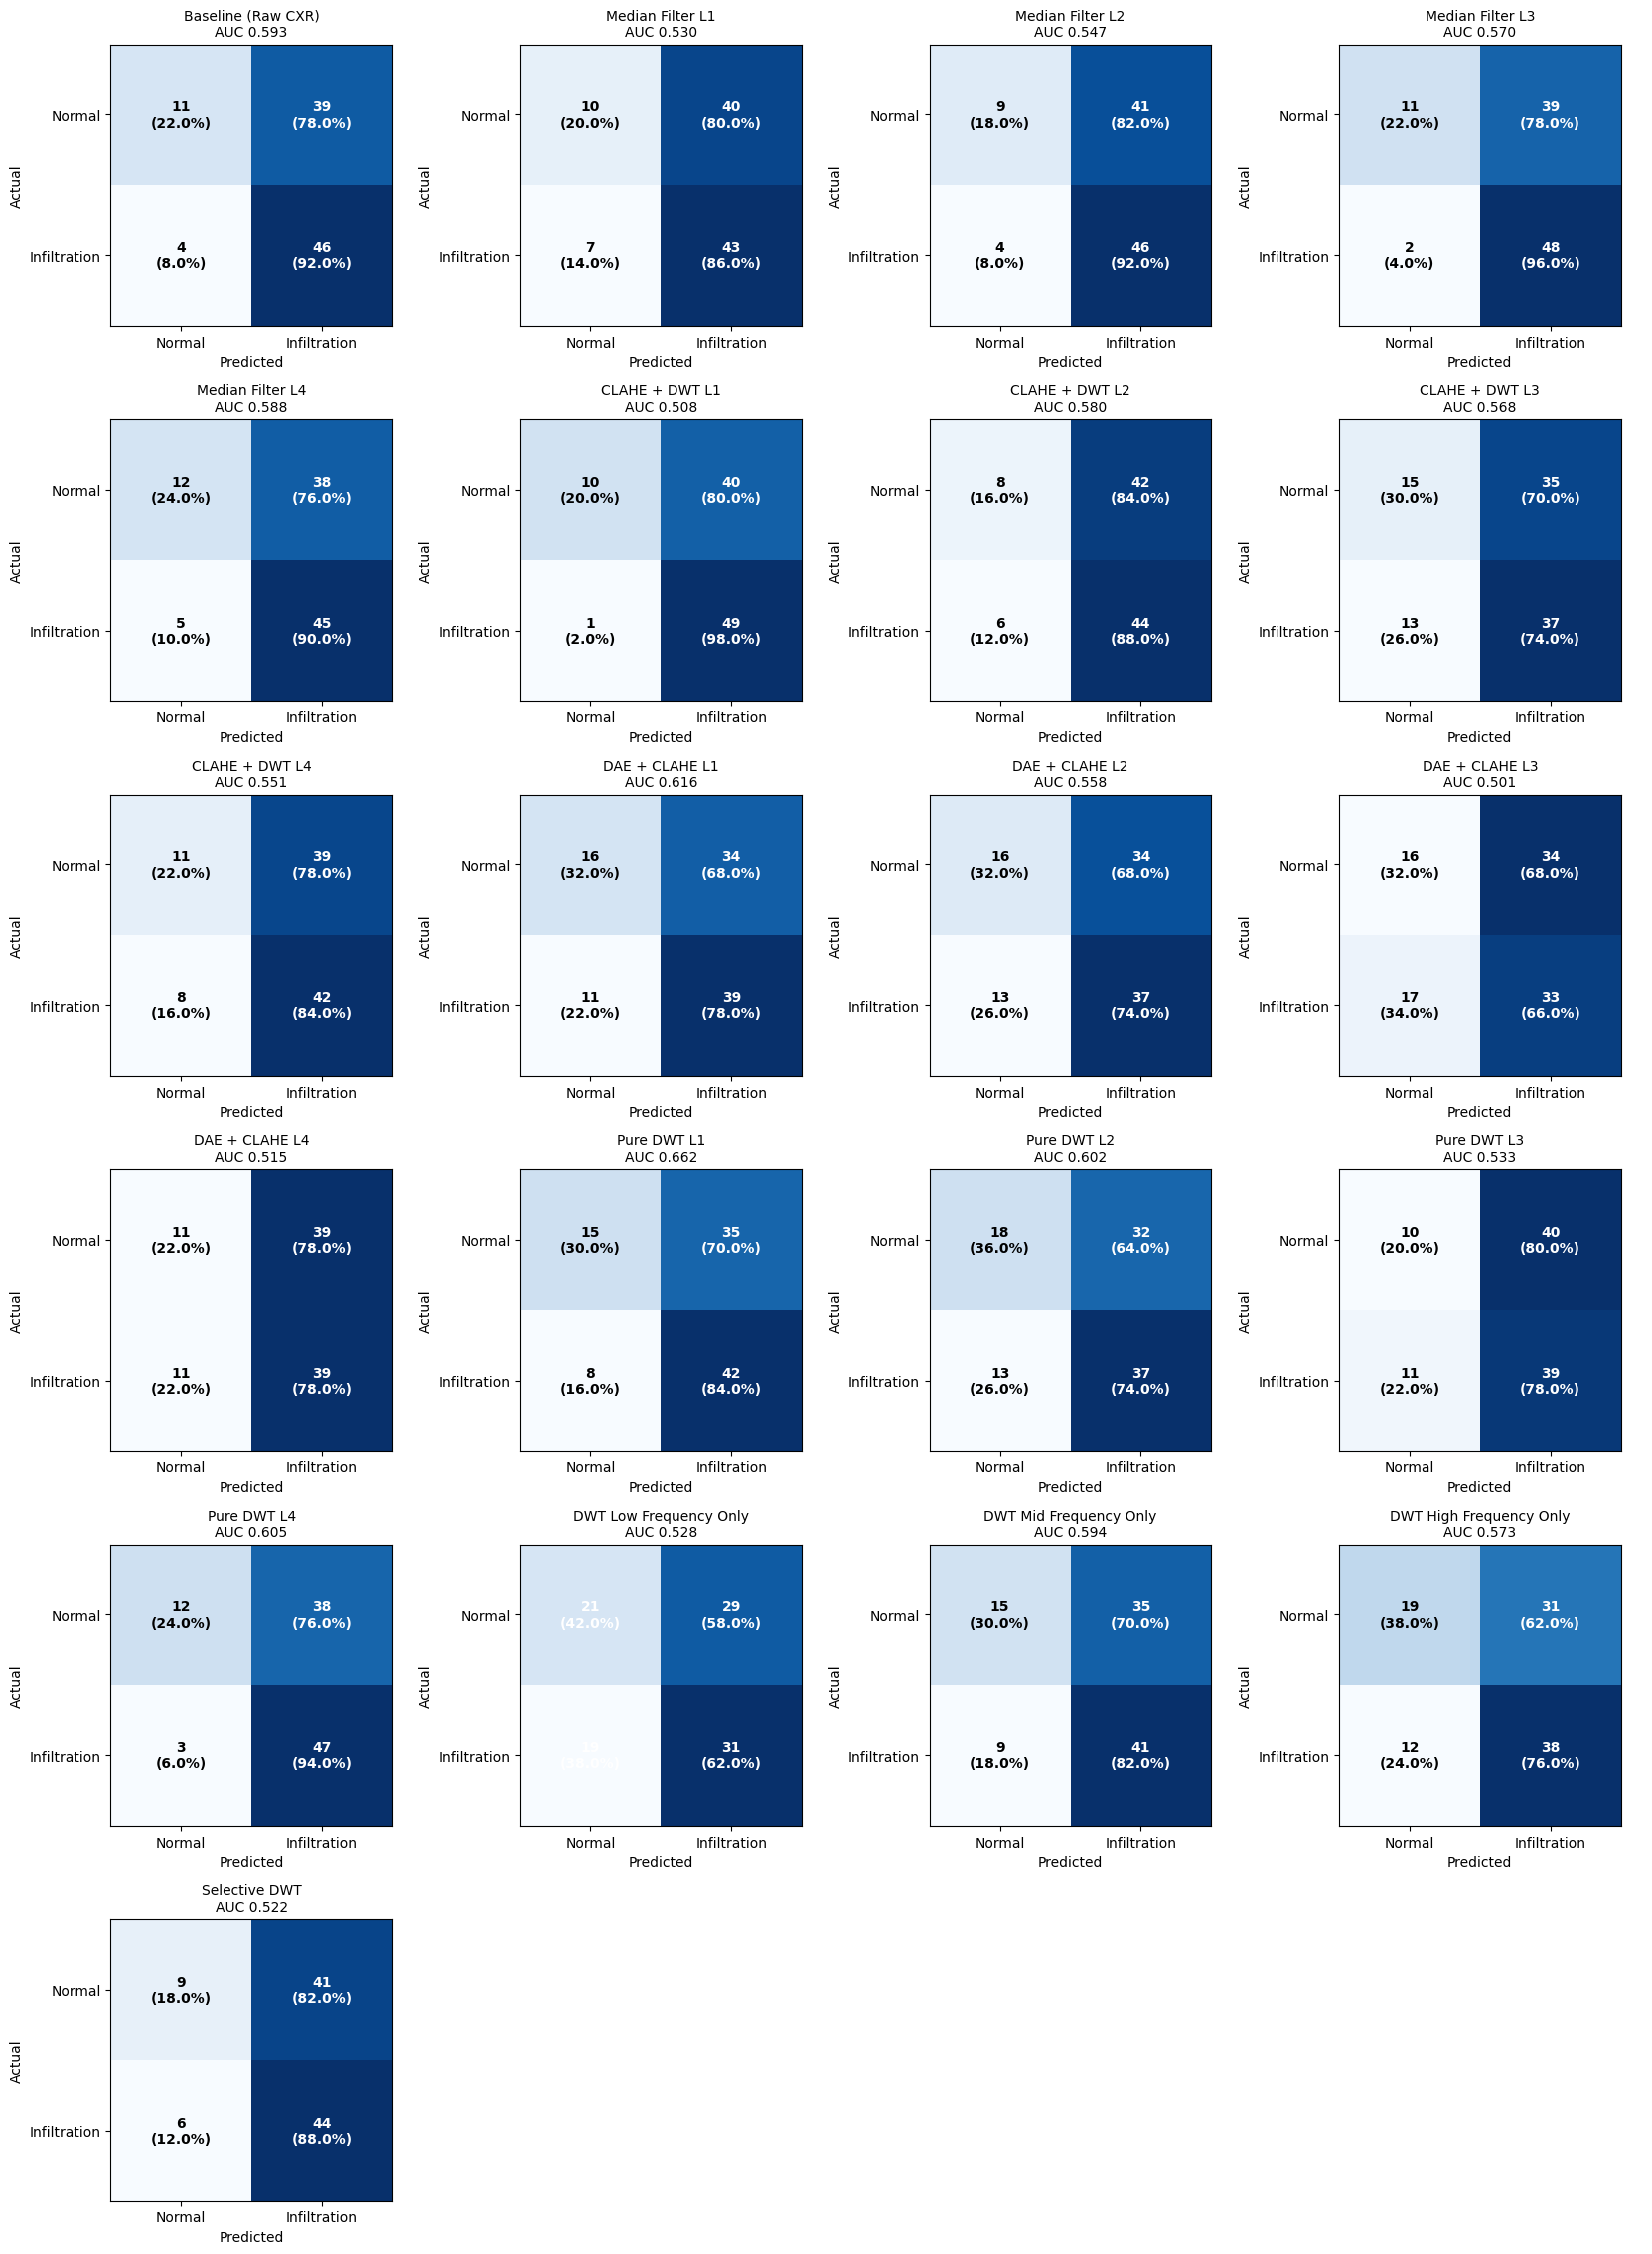

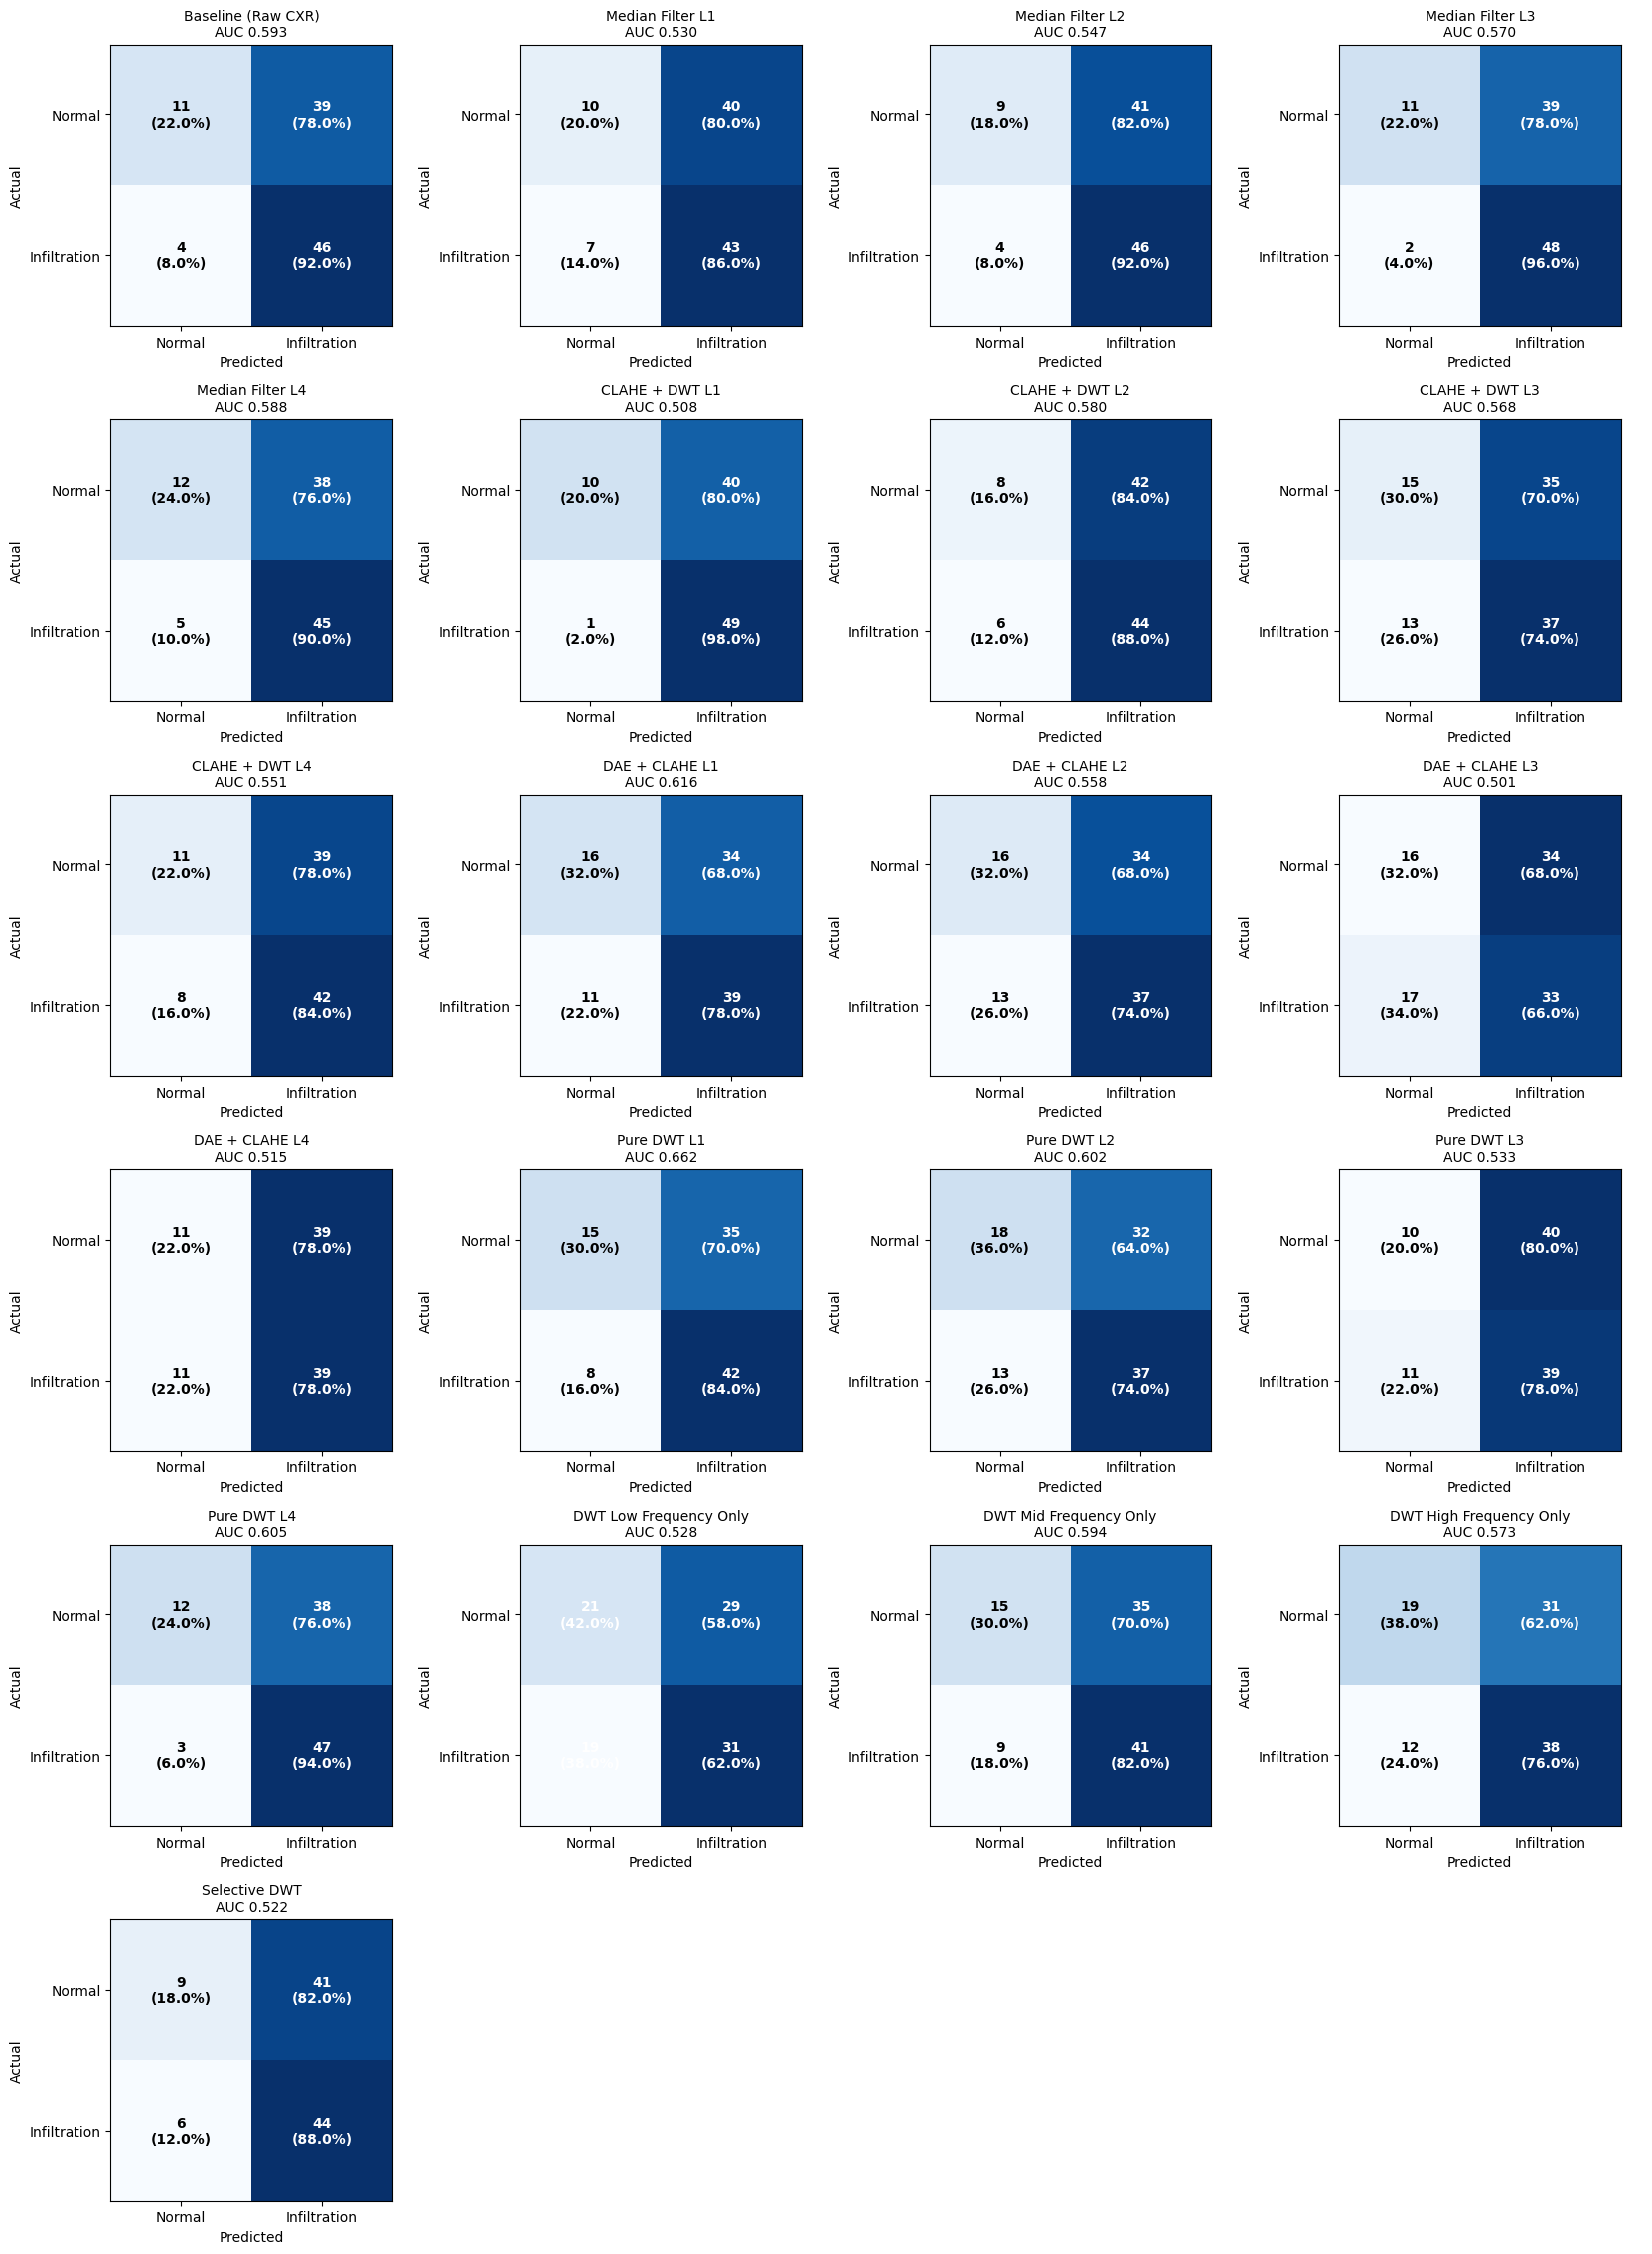

In [ ]:
import torch
table = summarize(OUT_DIR)
display(table.drop(columns="condition_id").style.format(
    {"Accuracy": "{:.4f}", "Precision": "{:.4f}", "Recall": "{:.4f}", "F1-Score": "{:.4f}", "ROC-AUC": "{:.4f}"}))
print("Saved:", OUT_DIR / "results_class200.csv")
plot_confusions(OUT_DIR)


## ตัวอย่างภาพ test หนึ่งภาพผ่านทุกวิธี

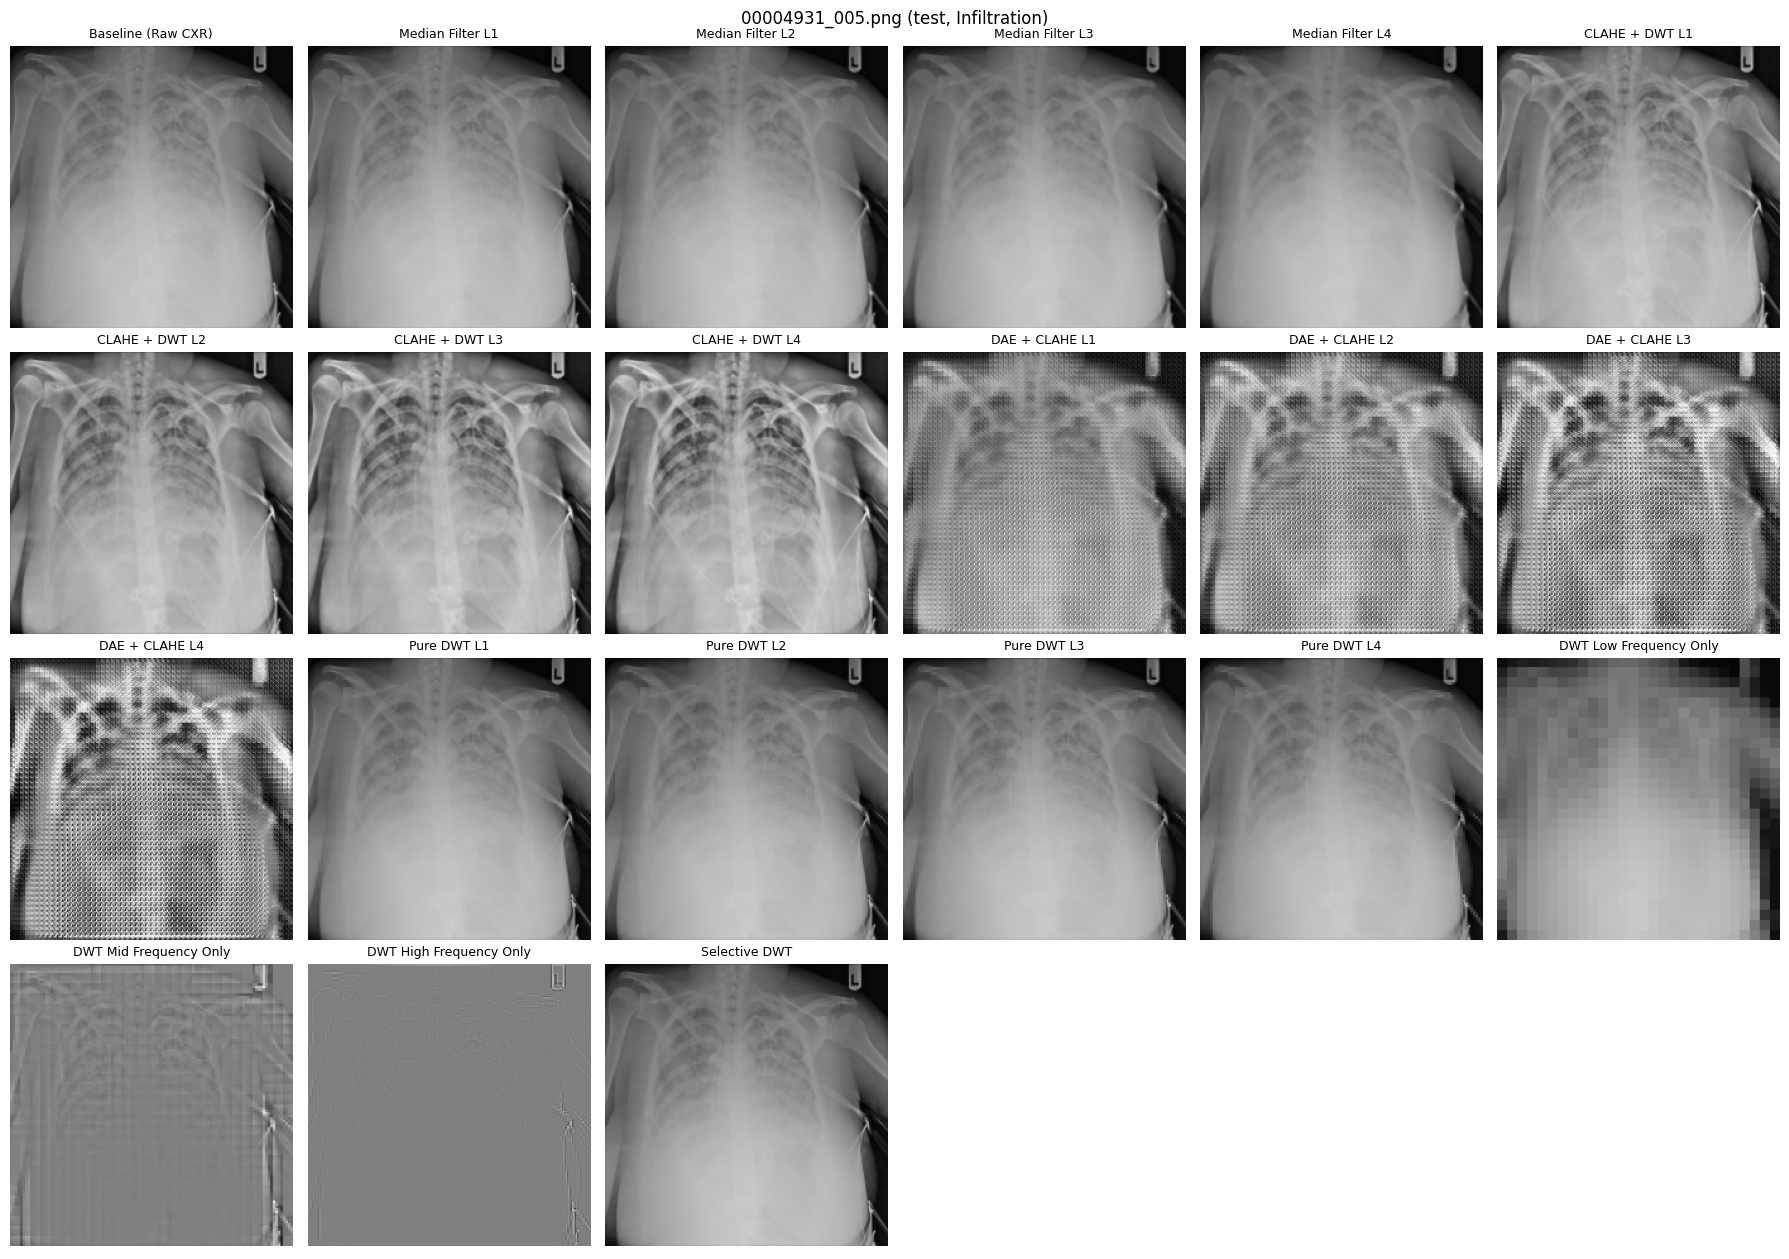

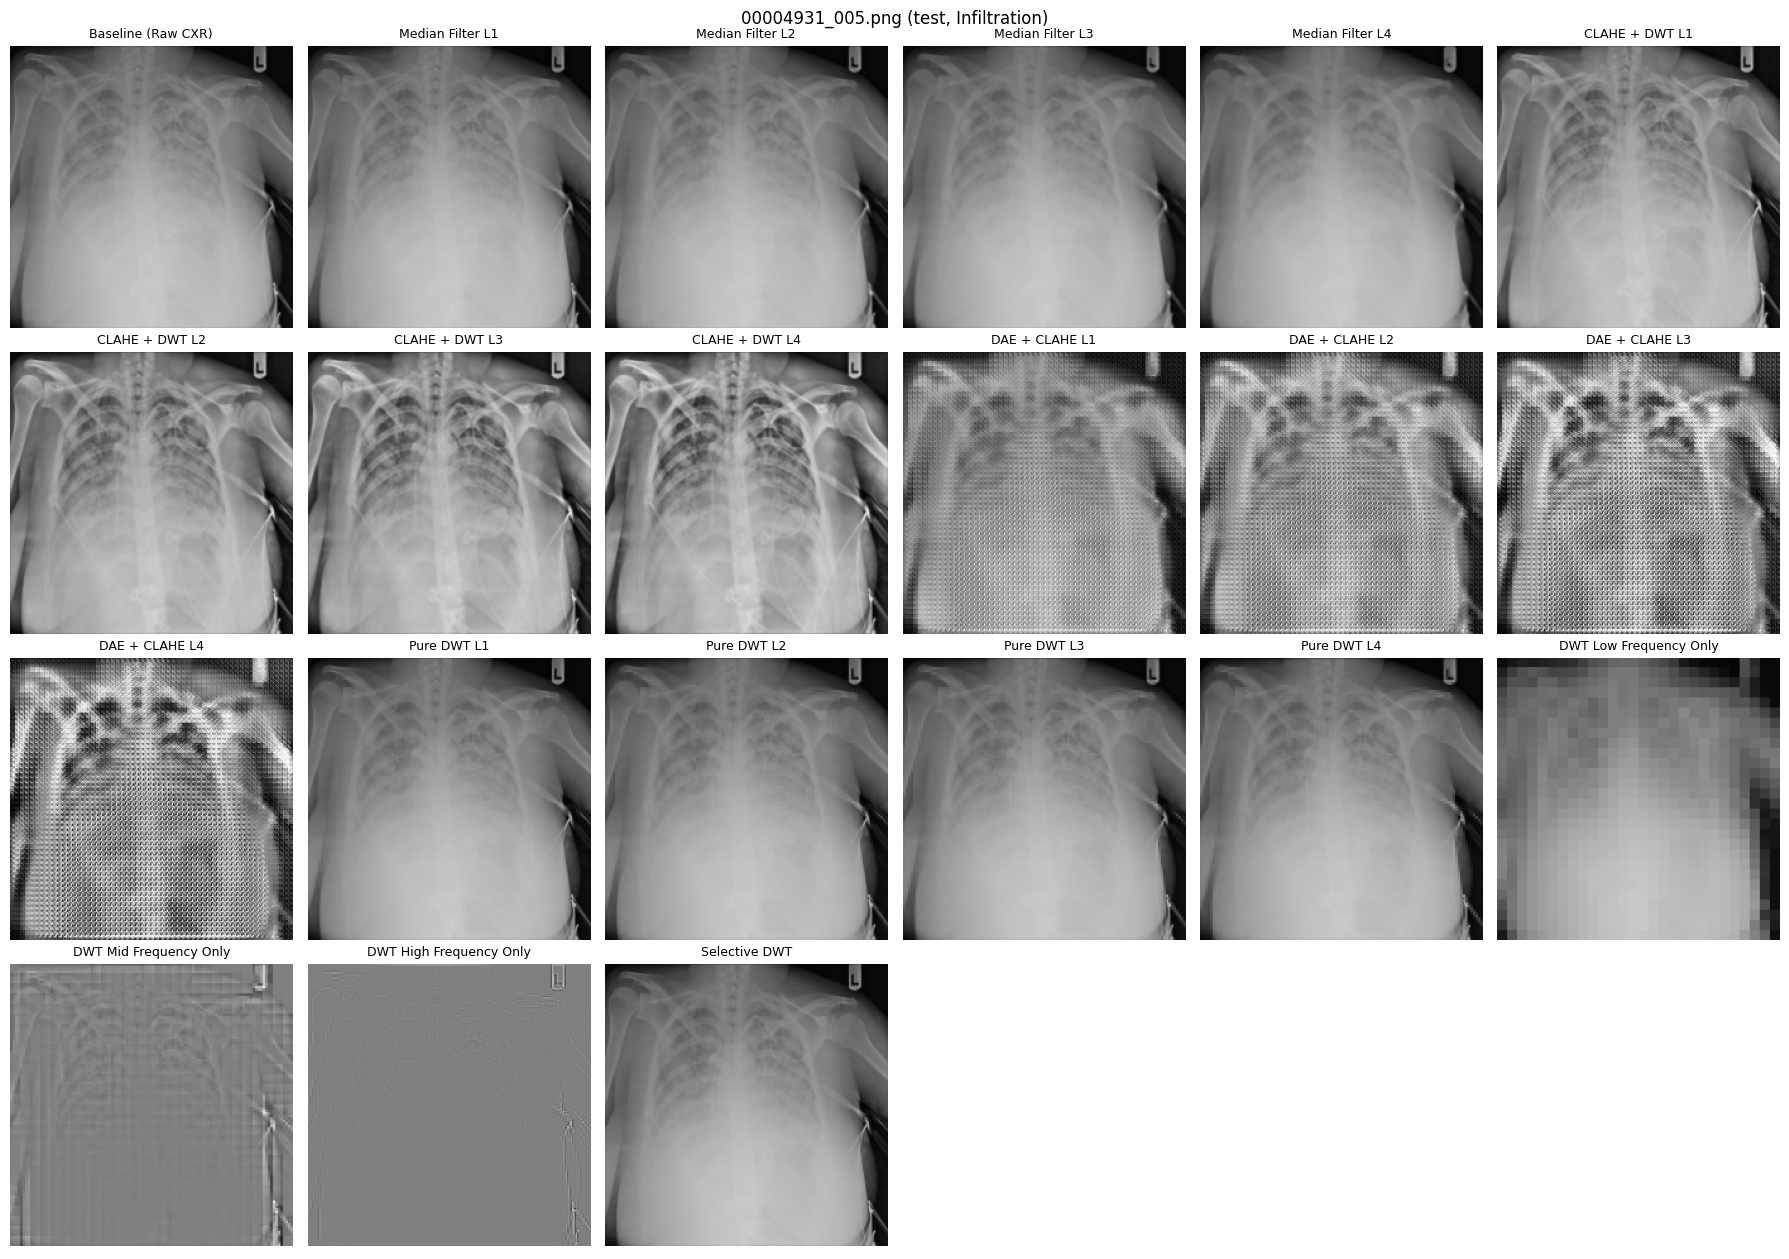

In [ ]:
dae = None
if (OUT_DIR / "dae.pt").exists():
    dae = ConvDAE()
    dae.load_state_dict(torch.load(OUT_DIR / "dae.pt", map_location="cpu", weights_only=False)["state"])
    dae.eval()
plot_examples(DATA_DIR, OUT_DIR, dae=dae)
